In [86]:
##% imports
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
import seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests

from popy.io_tools import load_behavior, load_eye_data, clean_eye
from popy.behavior_data_tools import add_switch_info, add_trial_in_block, add_date_of_recordig, drop_time_fields
from popy.config import COLORS

# fontsize 8
plt.rcParams.update({'font.size': 8})

# injection types and their colors
INJECTIONS = ['none', 'sham', 'DCZ', 'MISSING']
INJECTION_COLORS = {'none': 'grey',          # grey
                    'DCZ': '#4CBB17',        # poison green
                    'sham': "#124BA0",       # deep blue
                    'MISSING': '#8B0000'}    # deep red

def plot_mean_heatmaps_per_target(heatmaps, targets, xlims, ylims):
    # plot mean heatmaps per target. color it in a scale that goes from white to the target color
    plt.figure(figsize=(12, 4))
    for i, target in enumerate(np.unique(targets)):
        if np.isnan(target):  # skip NaN targets
            continue
        target_ids = targets == target
        mean_heatmap = np.mean(heatmaps[target_ids], axis=0)

        # build a cmap that goes from white to the target color
        cmap_target_specific = sns.light_palette(COLORS[f'target_{int(target)}'], as_cmap=True)

        plt.subplot(1, len(np.unique(targets)), i + 1)
        plt.imshow(mean_heatmap, extent=[xlims[0], xlims[1], ylims[0], ylims[1]], origin='lower', cmap=cmap_target_specific, aspect='equal', interpolation='nearest')
        plt.colorbar(label='Count', shrink=0.4)
        plt.title(f'Mean Heatmap for Target {int(target)}')
        plt.xlabel('Horizontal Position (deg)')
        plt.ylabel('Vertical Position (deg)')

    plt.tight_layout()
    plt.show()

def smooth_mean_padded(trajectory, window_size=5):
    pad_width = window_size // 2
    kernel = np.ones(window_size) / window_size
    padded = np.pad(trajectory, pad_width, mode="mean")
    return np.convolve(padded, kernel, mode="valid")


def plot_pupil_trajectories_by_outcome(trajectories, outcomes, t_before, t_after, session):        
    fig, ax = plt.subplots(figsize=(10, 5))
    # plot per-outcome pupil size trajectories, colors are under COLORS['rewarded'] and COLORS['unrewarded']
    traj_rewarded = trajectories[outcomes == 1]
    traj_unrewarded = trajectories[outcomes == 0]

    traj_mean_rewarded = np.nanmean(traj_rewarded, axis=0)
    traj_mean_unrewarded = np.nanmean(traj_unrewarded, axis=0)


    time_axis = np.linspace(-t_before, t_after, trajectories.shape[1])
    ax.plot(time_axis, traj_mean_rewarded, color=COLORS['rewarded'], label='Rewarded')
    ax.plot(time_axis, traj_mean_unrewarded, color=COLORS['unrewarded'], label='Unrewarded')
    
    ax.axvline(0, color='k', linestyle='--', label='Feedback')
    ax.set_xlabel('Time (s) relative to feedback')
    ax.set_ylabel('Pupil Size (a.u.)')
    ax.set_title(f'Pupil Size Trajectories across sessions')
    ax.legend()

    plt.tight_layout()
    plt.show()

def plot_pupil_trajectories_by_outcome_and_injection(trajectories, outcomes, injection,t_before, t_after, session):        
    fig, ax = plt.subplots(figsize=(10, 5))
    # plot per-outcome pupil size trajectories, colors are under COLORS['rewarded'] and COLORS['unrewarded']
    traj_rewarded_sham = trajectories[(outcomes == 1) & (injection == "sham")]
    traj_unrewarded_sham = trajectories[(outcomes == 0) & (injection == "sham")]
    traj_rewarded_DCZ = trajectories[(outcomes == 1) & (injection == "DCZ")]
    traj_unrewarded_DCZ = trajectories[(outcomes == 0) & (injection == "DCZ")]

    traj_mean_rewarded_sham = np.nanmean(traj_rewarded_sham, axis=0)
    traj_mean_unrewarded_sham = np.nanmean(traj_unrewarded_sham, axis=0)
    traj_mean_rewarded_DCZ = np.nanmean(traj_rewarded_DCZ, axis=0)
    traj_mean_unrewarded_DCZ = np.nanmean(traj_unrewarded_DCZ, axis=0)

    # smooth with pading
    traj_mean_rewarded_DCZ = smooth_mean_padded(traj_mean_rewarded_DCZ, window_size=5)
    traj_mean_unrewarded_DCZ = smooth_mean_padded(traj_mean_unrewarded_DCZ, window_size=5)
    traj_mean_rewarded_sham = smooth_mean_padded(traj_mean_rewarded_sham, window_size=5)
    traj_mean_unrewarded_sham = smooth_mean_padded(traj_mean_unrewarded_sham, window_size=5)

    time_axis = np.linspace(-t_before, t_after, trajectories.shape[1])
    ax.plot(time_axis, traj_mean_rewarded_sham, color=COLORS['rewarded'], label='Rewarded (Sham)')
    ax.plot(time_axis, traj_mean_unrewarded_sham, color=COLORS['unrewarded'], label='Unrewarded (Sham)')
    ax.plot(time_axis, traj_mean_rewarded_DCZ, color=COLORS['rewarded'], label='Rewarded (DCZ)', linestyle='--')
    ax.plot(time_axis, traj_mean_unrewarded_DCZ, color=COLORS['unrewarded'], label='Unrewarded (DCZ)', linestyle='--')

    ax.axvline(0, color='k', linestyle='--', label='Feedback')
    ax.set_xlabel('Time (s) relative to feedback')
    ax.set_ylabel('Pupil Size (a.u.)')
    ax.set_title(f'Pupil Size Trajectories across sessions')
    ax.legend()

    plt.tight_layout()
    plt.show()

In [2]:
# load all sessions of monkey yu
behav = load_behavior('yu')
behav

,monkey,injection,session,trial_id,trial_start_time,n_target_touches,lever_touch_time,lever_validation_time,lever_release_time,target_touch_time,...,target,feedback,n_events,n_early_lever_release,n_late_lever_touch,n_premature_target_touch,n_early_target_release,n_late_target_touch_after_reward,n_late_target_touch_after_no_reward,n_false_touch
8790,yu,sham,010224,0,406.6467,1.0,408.4805,410.0001,410.6925,411.0273,...,3.0,1.0,14,0,0,0,0,0,0,0
8791,yu,sham,010224,1,413.0286,1.0,413.3798,414.9007,415.6568,415.8628,...,3.0,0.0,13,0,0,0,0,0,0,0
8792,yu,sham,010224,2,417.8087,1.0,426.7609,428.2762,429.3186,429.5576,...,3.0,0.0,29,2,0,2,0,0,1,5
8793,yu,sham,010224,3,431.5503,1.0,432.8637,434.3738,435.8459,436.0895,...,3.0,1.0,19,0,0,1,0,1,0,2
8794,yu,sham,010224,4,438.2179,1.0,438.5759,440.0940,440.8073,441.0272,...,3.0,0.0,20,0,0,0,0,0,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20361,yu,sham,311023,601,6217.0367,2.0,6222.9790,6224.4904,6224.7375,6225.7623,...,3.0,1.0,34,6,0,0,1,0,0,7
20362,yu,sham,311023,602,6227.7006,1.0,6227.9874,6229.5040,6229.8453,6230.0463,...,3.0,0.0,17,0,0,0,0,0,1,1
20363,yu,sham,311023,603,6232.0158,1.0,6232.3439,6233.8539,6234.1947,6234.4082,...,3.0,1.0,20,0,0,1,0,1,0,2
20364,yu,sham,311023,604,6236.3478,1.0,6243.8547,6245.3652,6245.7283,6245.9409,...,3.0,1.0,30,5,0,0,0,1,0,6


Processing session 010224 (1/37)


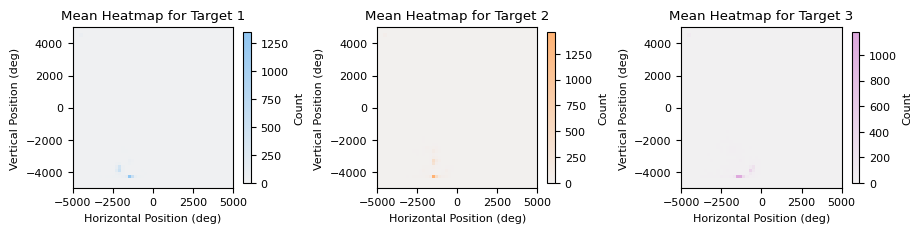

Processing session 011223 (2/37)


KeyboardInterrupt: 

In [3]:
# load eye data

xlims, ylims = [-5000, 5000], [-5000, 5000]
n_bins = 50


for i, session in enumerate(behav.session.unique()):
    print(f'Processing session {session} ({i+1}/{len(behav.session.unique())})')
    
    eye_time, eye_pos, pupil_size = load_eye_data('yu', session)
    #eye_pos, pupil_size = clean_eye(eye_pos, pupil_size)

    heatmaps = []
    targets = []

    behav_temp = behav[behav['session'] == session]
    for trial_id in behav_temp['trial_id'].unique():
        trial_data = behav_temp[behav_temp['trial_id'] == trial_id]

        trial_start = trial_data['trial_start_time'].values[0]
        trial_end = trial_data['feedback_time'].values[0]
        trial_target = trial_data['target'].values[0]

        trial_mask = (eye_time >= trial_start) & (eye_time <= trial_end)
        trajectory_temp = eye_pos[trial_mask]
        heatmap_temp, xedges, yedges = np.histogram2d(trajectory_temp[:, 0], trajectory_temp[:, 1], bins=n_bins, range=[xlims, ylims])

        heatmaps.append(heatmap_temp.T)
        targets.append(trial_target)


    heatmaps = np.array(heatmaps)

    plot_mean_heatmaps_per_target(heatmaps, np.array(targets), xlims, ylims)

    if i > 5: break



# Analyze eye tracking

Things to check:
- eye position heatmap per selected target (good validation)
  - same but restricted to target selection period (+- 1 sec from target touch)
  
Pupil size
- in time per positive/negative outcome
  - further split by sham/dcz
- in time per RPE and value
  - further split by sham/dcz

In [79]:
def clear_pupil(pupil_size):
    
    pupil_size_lim = (-3950, 10000)

    pupil_size_good_ids = (pupil_size > pupil_size_lim[0]) & (pupil_size < pupil_size_lim[1])

    print(f"Percent good pupil size data: {pupil_size_good_ids.sum() / len(pupil_size_good_ids) * 100:.2f}%")
    
    # set nan
    pupil_size[~pupil_size_good_ids] = np.nan

    return pupil_size

In [80]:
# pupil size: per outcome and per RPE
t_before, t_after = 1.5, 2.5
sr = 1000  # sampling rate of pupil size data in Hz

trajectories_all = []
outcomes_all = []
injections_all = []

for i, session in enumerate(behav.session.unique()):
    print(f'Processing session {session} ({i+1}/{len(behav.session.unique())})')
    
    eye_time, _, pupil_size = load_eye_data('yu', session)
    pupil_size = clear_pupil(pupil_size)

    behav_temp = behav[behav['session'] == session]

    n_before = round(t_before * sr)       # 1500
    n_after = round(t_after * sr)         # 1500
    n_samples = n_before + n_after        # 3000

    trajectories = []

    for trial_pos, (_, trial_data) in enumerate(behav_temp.iterrows()):
        fb_time = trial_data["feedback_time"]
        target = trial_data["target"]
        outcome = trial_data["feedback"]
        injection = trial_data["injection"]

        # First eye-data sample at or after feedback
        fb_idx = np.searchsorted(eye_time, fb_time)

        start_idx = fb_idx - n_before
        end_idx = fb_idx + n_after         # exclusive

        if start_idx >= 0 and end_idx <= len(pupil_size):

            trajectories_all.append(pupil_size[start_idx:end_idx])
            outcomes_all.append(outcome)
            injections_all.append(injection)

trajectories_all = np.array(trajectories_all)
outcomes_all = np.array(outcomes_all)
injections_all = np.array(injections_all)

Processing session 010224 (1/37)
Percent good pupil size data: 98.16%
Processing session 011223 (2/37)
Percent good pupil size data: 80.97%
Processing session 070224 (3/37)
Percent good pupil size data: 98.45%
Processing session 071123 (4/37)
Percent good pupil size data: 84.05%
Processing session 071223 (5/37)
Percent good pupil size data: 98.45%
Processing session 081123 (6/37)
Percent good pupil size data: 98.19%
Processing session 081223 (7/37)
Percent good pupil size data: 98.49%
Processing session 121223 (8/37)
Percent good pupil size data: 98.02%
Processing session 131223 (9/37)
Percent good pupil size data: 98.57%
Processing session 141123 (10/37)
Percent good pupil size data: 97.72%
Processing session 141223 (11/37)
Percent good pupil size data: 98.57%
Processing session 151123 (12/37)
Percent good pupil size data: 98.24%
Processing session 160124 (13/37)
Percent good pupil size data: 98.57%
Processing session 161123 (14/37)
Percent good pupil size data: 98.40%
Processing sess

In [95]:
mean_sham = np.nanmean(trajectories_all[injections_all == "sham"])
mean_dcz = np.nanmean(trajectories_all[injections_all == "DCZ"])
                      
print(f'Mean pupil size (sham): {mean_sham:.2f}')
print(f'Mean pupil size (DCZ): {mean_dcz:.2f}')

Mean pupil size (sham): -3502.72
Mean pupil size (DCZ): -3456.68


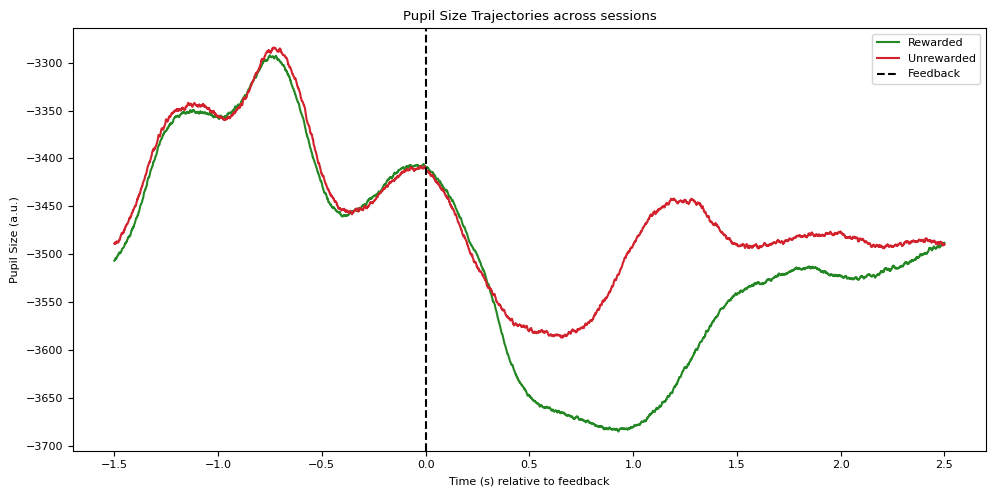

In [87]:
plot_pupil_trajectories_by_outcome(trajectories_all, outcomes_all, t_before, t_after, session)


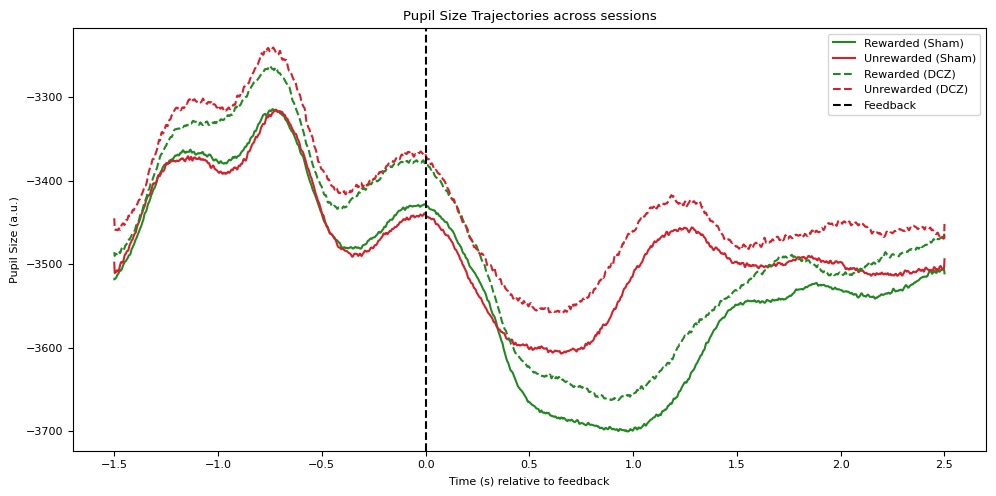

In [88]:
plot_pupil_trajectories_by_outcome_and_injection(trajectories_all, outcomes_all, injections_all, t_before, t_after, session)


/tmp/ipykernel_1574476/1579708305.py:41: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  boxplot = ax.boxplot(
/tmp/ipykernel_1574476/1579708305.py:21: RuntimeWarning: Mean of empty slice
  trial_means = np.nanmean(
/tmp/ipykernel_1574476/1579708305.py:41: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  boxplot = ax.boxplot(


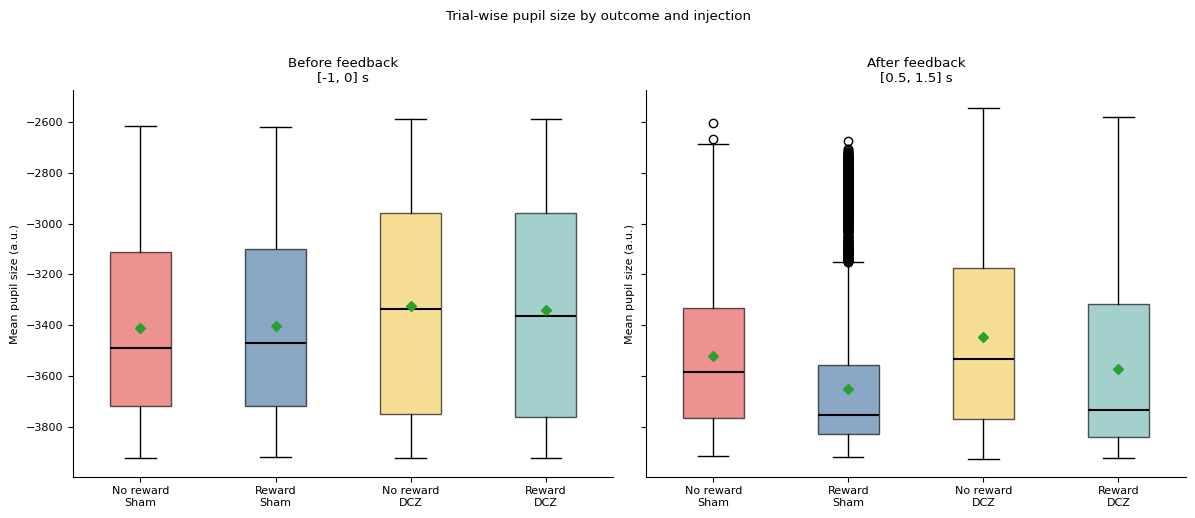

In [90]:
intervals = {
    "Before feedback\n[-1, 0] s": (-1.0, 0.0),
    "After feedback\n[0.5, 1.5] s": (0.5, 1.5),
}
sr = 1000

conditions = [
    ("No reward\nSham", (outcomes_all == 0) & (injections_all == "sham"), "#E45756"),
    ("Reward\nSham", (outcomes_all == 1) & (injections_all == "sham"), "#4C78A8"),
    ("No reward\nDCZ", (outcomes_all == 0) & (injections_all == "DCZ"), "#F2CF5B"),
    ("Reward\nDCZ", (outcomes_all == 1) & (injections_all == "DCZ"), "#72B7B2"),
]

fig, axs = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for ax, (period, (window_start, window_end)) in zip(axs, intervals.items()):
    start_sample = int((t_before + window_start) * sr)
    end_sample = int((t_before + window_end) * sr)

    # One mean pupil-size value per trial in this time window
    trial_means = np.nanmean(
        trajectories_all[:, start_sample:end_sample],
        axis=1,
    )

    values_by_condition = []
    labels = []
    colors = []

    for label, condition_mask, color in conditions:
        values = trial_means[condition_mask]
        values = values[np.isfinite(values)]

        if len(values) == 0:
            raise ValueError(f"No valid trials for condition: {label}")

        values_by_condition.append(values)
        labels.append(label)
        colors.append(color)

    boxplot = ax.boxplot(
        values_by_condition,
        patch_artist=True,
        labels=labels,
        showmeans=True,
        meanprops={"color": "black", "marker": "D", "markersize": 5},
        medianprops={"color": "black", "linewidth": 1.5},
    )

    for box, color in zip(boxplot["boxes"], colors):
        box.set_facecolor(color)
        box.set_alpha(0.65)

    ax.set_title(period)
    ax.set_ylabel("Mean pupil size (a.u.)")
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Trial-wise pupil size by outcome and injection", y=1.02)
fig.tight_layout()
plt.show()